In [1]:
import pandas as pd

# Direct link to the same file you downloaded, on the official UCI site
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

df = pd.read_csv(url, header=None, names=columns, na_values='?')

print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [2]:

# STAGE 1: DATA CLEANING, PREPARATION AND EXPLORATION
# 1.1 Understanding the dataset: features, target and data types


# Data types and non-null counts for every column
# (ca and thal should show fewer than 303 -> they have missing values)
df.info()

# Basic statistics for each feature (min/max give a first hint of outliers)
display(df.describe().T)

# Target distribution: 0 = no disease, 1-4 = disease severity
print(df['num'].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [3]:
# 1.2 Data quality checks: missing values and duplicates


# Count missing values per column, and their percentage of the dataset
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])
print(f"Rows with any missing value: {df.isnull().any(axis=1).sum()} "
      f"({df.isnull().any(axis=1).mean()*100:.1f}% of the data)")

# Show the rows that have missing values
display(df[df.isnull().any(axis=1)])

# Check for exact duplicate patients (same values in every column)
print(f"\nDuplicate rows: {df.duplicated().sum()}")

Missing values per column:
ca      4
thal    2
dtype: int64
Rows with any missing value: 6 (2.0% of the data)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0



Duplicate rows: 0


In [4]:
# 1.3 Inconsistent data check: are all values valid?


# Allowed codes for each categorical feature (from heart-disease.names on UCI)
valid_codes = {
    'sex': [0, 1], 'cp': [1, 2, 3, 4], 'fbs': [0, 1], 'restecg': [0, 1, 2],
    'exang': [0, 1], 'slope': [1, 2, 3], 'ca': [0, 1, 2, 3], 'thal': [3, 6, 7],
    'num': [0, 1, 2, 3, 4]
}

# Find any value that is not in the allowed list (ignoring the missing ones)
for col, codes in valid_codes.items():
    invalid = df[col].dropna()[~df[col].dropna().isin(codes)]
    print(f"{col:8s} values: {sorted(df[col].dropna().unique())}  -> invalid: {len(invalid)}")

# Numeric features: values must be physically possible (greater than 0)
numeric_cols = ['age', 'trestbps', 'chol', 'thalach']
print("\nImpossible zero/negative values:")
print((df[numeric_cols] <= 0).sum())

sex      values: [np.float64(0.0), np.float64(1.0)]  -> invalid: 0
cp       values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]  -> invalid: 0
fbs      values: [np.float64(0.0), np.float64(1.0)]  -> invalid: 0
restecg  values: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]  -> invalid: 0
exang    values: [np.float64(0.0), np.float64(1.0)]  -> invalid: 0
slope    values: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]  -> invalid: 0
ca       values: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]  -> invalid: 0
thal     values: [np.float64(3.0), np.float64(6.0), np.float64(7.0)]  -> invalid: 0
num      values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]  -> invalid: 0

Impossible zero/negative values:
age         0
trestbps    0
chol        0
thalach     0
dtype: int64


age       normal range [28.5, 80.5] -> 0 outliers: []
trestbps  normal range [90.0, 170.0] -> 9 outliers: [172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180.0, 192.0, 200.0]
chol      normal range [115.0, 371.0] -> 5 outliers: [394.0, 407.0, 409.0, 417.0, 564.0]
thalach   normal range [84.8, 214.8] -> 1 outliers: [71.0]
oldpeak   normal range [-2.4, 4.0] -> 5 outliers: [4.2, 4.2, 4.4, 5.6, 6.2]


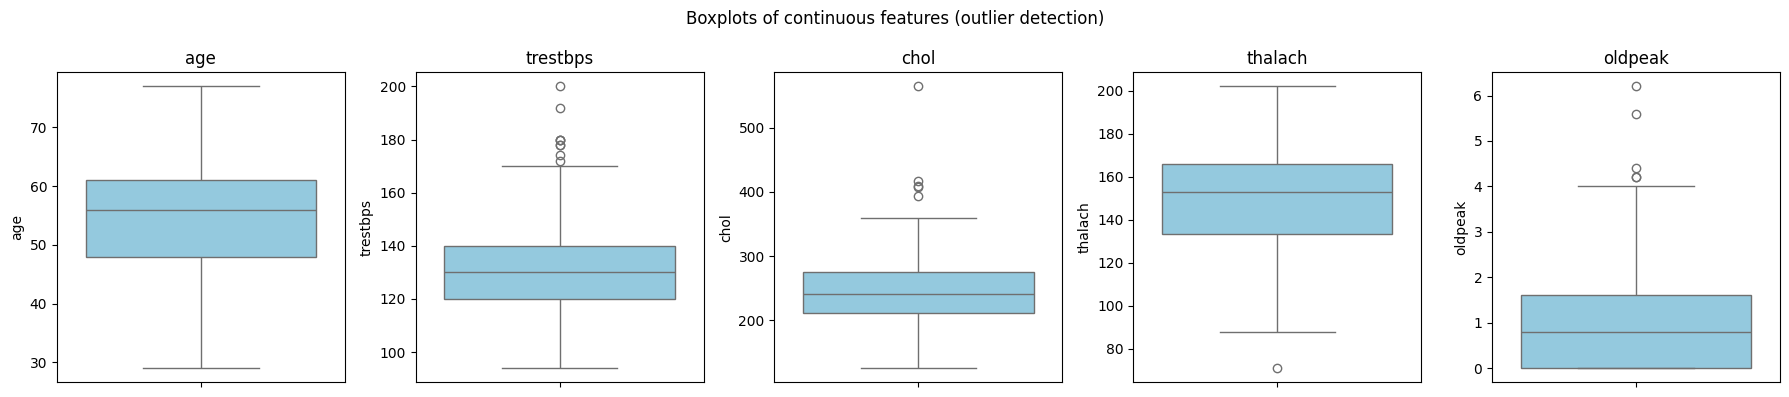

In [5]:
# 1.4 Outlier detection (IQR method + boxplots)

import matplotlib.pyplot as plt
import seaborn as sns

continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# IQR rule: flag values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
for col in continuous_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < low) | (df[col] > high)][col]
    print(f"{col:9s} normal range [{low:.1f}, {high:.1f}] -> {len(outliers)} outliers: {sorted(outliers.tolist())}")

# Boxplots: the dots outside the whiskers are the outliers
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.suptitle('Boxplots of continuous features (outlier detection)')
plt.tight_layout()
plt.show()

target
0    164
1    139
Name: count, dtype: int64
target
0    54.1%
1    45.9%
Name: count, dtype: object


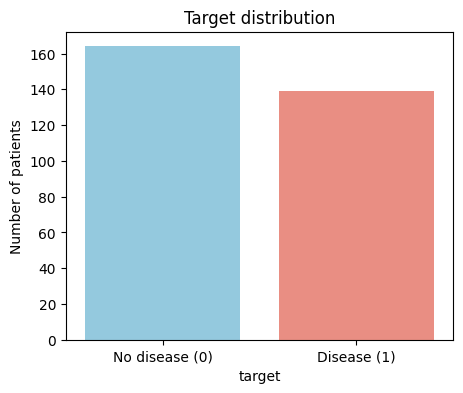

In [6]:
# 1.5 Target engineering: convert num (0-4) into a binary target


# 0 = no heart disease, 1-4 = heart disease present (any severity) -> 1
df['target'] = (df['num'] > 0).astype(int)
df = df.drop(columns='num')   # drop the old column so it can't leak into the features

# Check the new class balance
counts = df['target'].value_counts().sort_index()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + '%')

# Bar plot of the target distribution (EDA figure for the report)
plt.figure(figsize=(5, 4))
sns.countplot(x='target', hue='target', data=df, palette=['skyblue', 'salmon'], legend=False)
plt.xticks([0, 1], ['No disease (0)', 'Disease (1)'])
plt.title('Target distribution')
plt.ylabel('Number of patients')
plt.show()

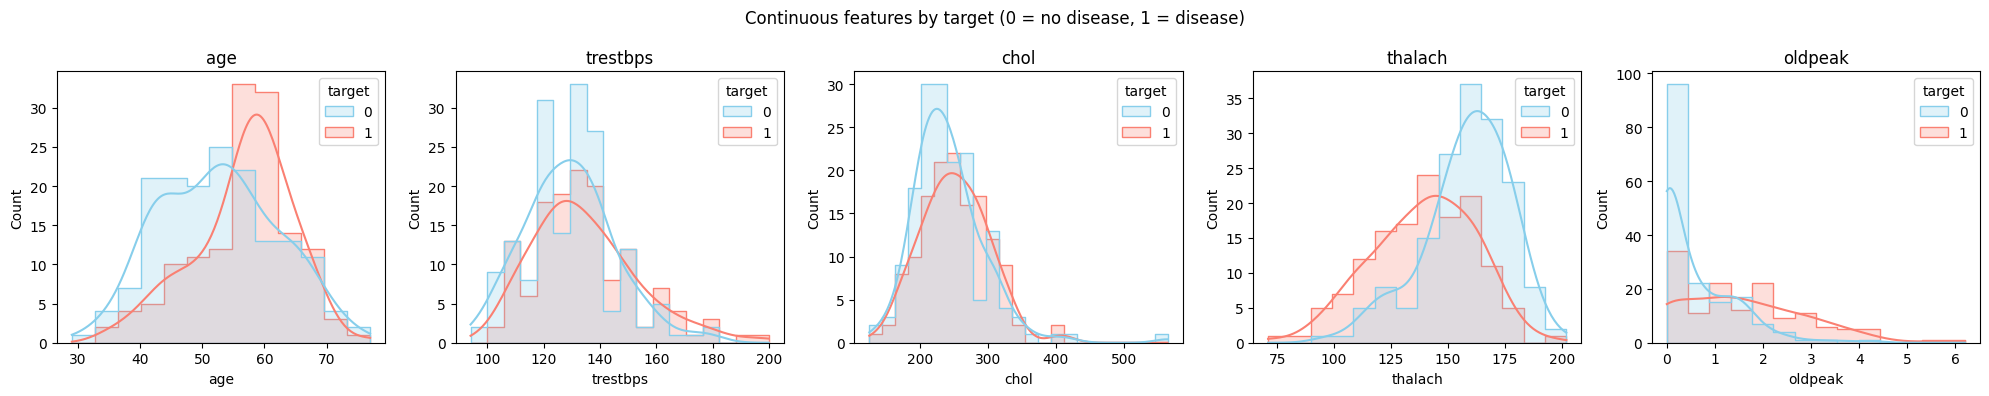

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0,52.6,129.2,242.6,158.4,0.6
1,56.6,134.6,251.5,139.3,1.6


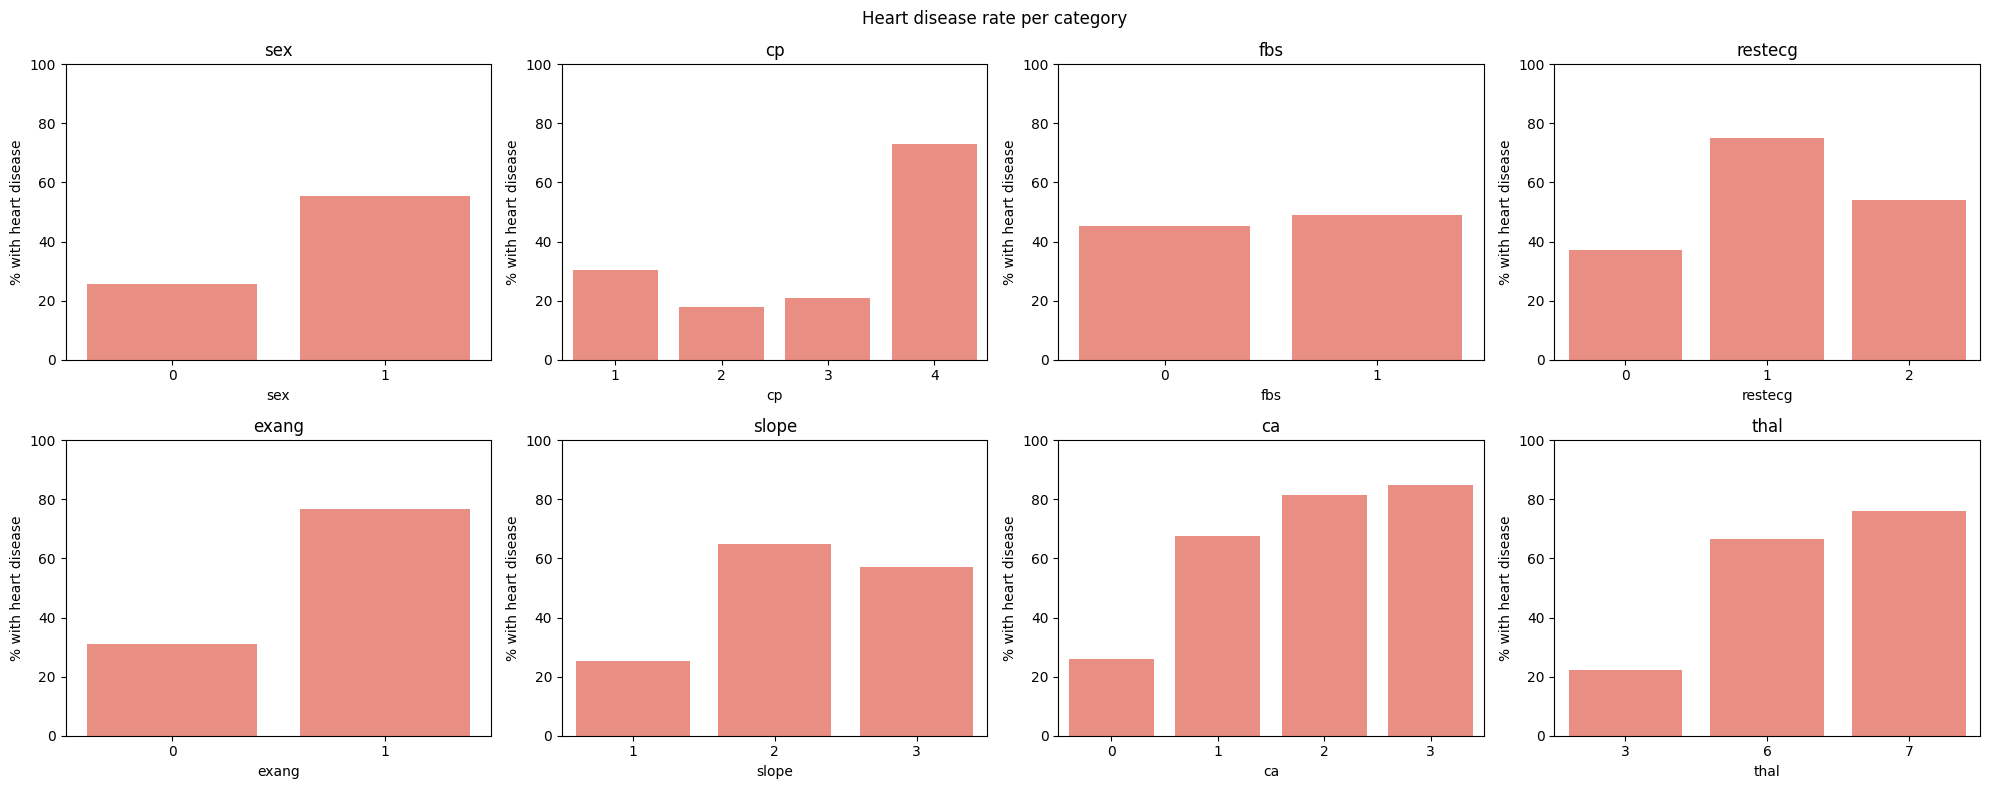

In [7]:

# 1.6 Exploratory Data Analysis (EDA): features vs target

categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# (a) Continuous features: distribution for healthy vs diseased patients
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, continuous_cols):
    sns.histplot(data=df, x=col, hue='target', kde=True, element='step',
                 palette=['skyblue', 'salmon'], ax=ax)
    ax.set_title(col)
plt.suptitle('Continuous features by target (0 = no disease, 1 = disease)')
plt.tight_layout()
plt.show()

# Average of each continuous feature in each group
display(df.groupby('target')[continuous_cols].mean().round(1))

# (b) Categorical features: % of patients with disease in each category
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flatten(), categorical_cols):
    rate = df.groupby(col)['target'].mean() * 100
    sns.barplot(x=rate.index.astype(int).astype(str), y=rate.values, ax=ax, color='salmon')
    ax.set_title(col)
    ax.set_ylabel('% with heart disease')
    ax.set_ylim(0, 100)
plt.suptitle('Heart disease rate per category')
plt.tight_layout()
plt.show()

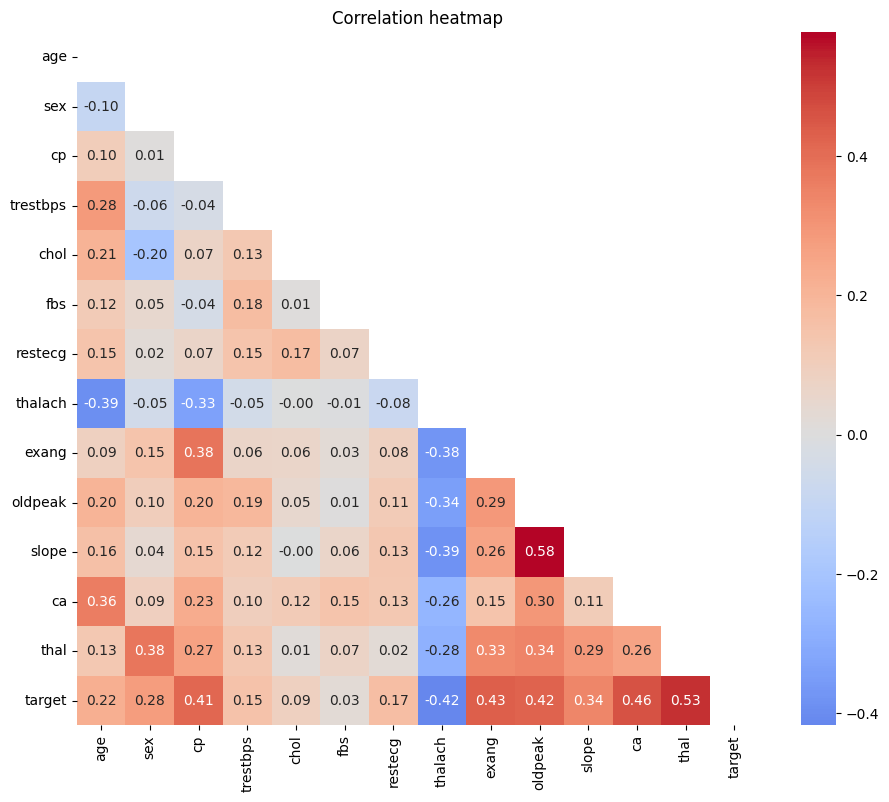

thal        0.53
ca          0.46
exang       0.43
oldpeak     0.42
thalach    -0.42
cp          0.41
slope       0.34
sex         0.28
age         0.22
restecg     0.17
trestbps    0.15
chol        0.09
fbs         0.03
Name: target, dtype: float64


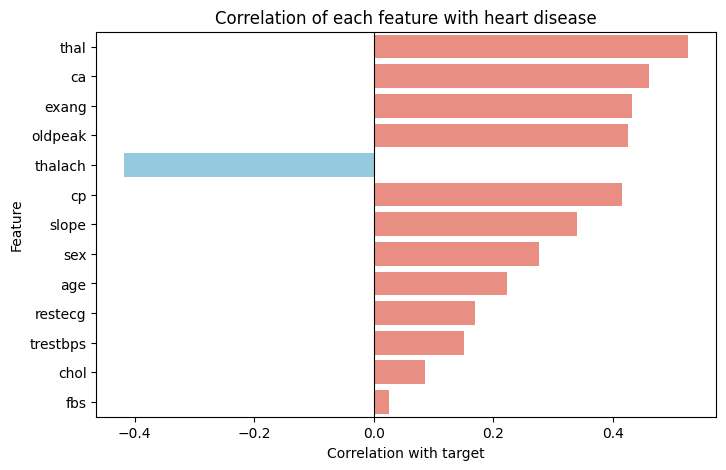

In [8]:
# 1.7 Feature relevance: correlation analysis

import numpy as np

# (a) Correlation heatmap: relationships between all features and the target
corr = df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            mask=np.triu(np.ones_like(corr, dtype=bool)))  # show the lower triangle only
plt.title('Correlation heatmap')
plt.show()

# (b) Ranking: how strongly each feature is correlated with the target
target_corr = corr['target'].drop('target')
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)
print(target_corr.round(2))

plt.figure(figsize=(8, 5))
colors = ['salmon' if v > 0 else 'skyblue' for v in target_corr.values]
sns.barplot(x=target_corr.values, y=target_corr.index,
            hue=target_corr.index, palette=colors, legend=False)
plt.ylabel('Feature')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of each feature with heart disease')
plt.xlabel('Correlation with target')
plt.show()

In [9]:

# STAGE 2: DATA SPLITTING (train / validation / test = 70 / 15 / 15)

from sklearn.model_selection import train_test_split

X = df.drop(columns='target')   # the 13 features
y = df['target']                # the binary target

# Step 1: set aside 15% as the TEST set (used only once, at the very end)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)

# Step 2: split the remaining 85% into TRAIN (70%) and VALIDATION (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=42)

# Check the sizes and that each set keeps the same disease ratio
for name, X_part, y_part in [('Train', X_train, y_train),
                             ('Validation', X_val, y_val),
                             ('Test', X_test, y_test)]:
    print(f"{name:10s}: {len(X_part):3d} patients ({len(X_part)/len(X)*100:.0f}%)  "
          f"-> disease rate {y_part.mean()*100:.1f}%")

Train     : 211 patients (70%)  -> disease rate 46.0%
Validation:  46 patients (15%)  -> disease rate 45.7%
Test      :  46 patients (15%)  -> disease rate 45.7%


In [10]:
# 1.8 Preprocessing: imputation, encoding and scaling
#     (fitted on the TRAINING set only, to avoid data leakage)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Group the features by type
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']  # numbers / counts
binary_features  = ['sex', 'fbs', 'exang']                                  # already 0/1
nominal_features = ['cp', 'restecg', 'slope', 'thal']                       # category codes

# Numeric: fill missing with the median, then standardize (mean 0, std 1)
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

# Nominal: fill missing with the most frequent category, then one-hot encode
nominal_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('bin', 'passthrough', binary_features),
    ('nom', nominal_pipe, nominal_features)])

# FIT on train only, then TRANSFORM all three sets with what was learned
X_train_p = preprocessor.fit_transform(X_train)
X_val_p   = preprocessor.transform(X_val)
X_test_p  = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Shapes:", X_train_p.shape, X_val_p.shape, X_test_p.shape)
print("Missing values left:", np.isnan(X_train_p).sum(), np.isnan(X_val_p).sum(), np.isnan(X_test_p).sum())
print("Final features:", list(feature_names))

Shapes: (211, 22) (46, 22) (46, 22)
Missing values left: 0 0 0
Final features: ['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'num__ca', 'bin__sex', 'bin__fbs', 'bin__exang', 'nom__cp_1.0', 'nom__cp_2.0', 'nom__cp_3.0', 'nom__cp_4.0', 'nom__restecg_0.0', 'nom__restecg_1.0', 'nom__restecg_2.0', 'nom__slope_1.0', 'nom__slope_2.0', 'nom__slope_3.0', 'nom__thal_3.0', 'nom__thal_6.0', 'nom__thal_7.0']


In [11]:
# STAGE 3: MODEL SELECTION AND DEVELOPMENT (traditional models)
# 3.1 Baseline models with default hyperparameters

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

def scores_for(model, X_part, y_part):
    """Accuracy, recall, F1 and ROC-AUC of a fitted model on one dataset."""
    pred = model.predict(X_part)
    prob = model.predict_proba(X_part)[:, 1]   # probability of disease, needed for ROC-AUC
    return [accuracy_score(y_part, pred), recall_score(y_part, pred),
            f1_score(y_part, pred), roc_auc_score(y_part, prob)]

rows = []
for name, model in baseline_models.items():
    model.fit(X_train_p, y_train)                     # train on the training set only
    train_s = scores_for(model, X_train_p, y_train)   # fit on data it has seen
    val_s = scores_for(model, X_val_p, y_val)         # performance on unseen patients
    rows.append([name, train_s[0]] + val_s)

baseline_results = pd.DataFrame(rows, columns=['Model', 'Train Accuracy', 'Val Accuracy',
                                               'Val Recall', 'Val F1', 'Val ROC-AUC']).round(3)
display(baseline_results)

,Model,Train Accuracy,Val Accuracy,Val Recall,Val F1,Val ROC-AUC
0,Logistic Regression,0.867,0.804,0.714,0.769,0.899
1,Random Forest,1.000,0.761,0.714,0.732,0.883


In [12]:
# =====================================================================
# STAGE 4 (traditional models): HYPERPARAMETER OPTIMIZATION
# Grid search with 5-fold stratified cross-validation on the TRAINING set
# =====================================================================
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 5 folds, each keeping the same disease ratio (stratified)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# The hyperparameter values to try for each model
param_grids = {
    'Logistic Regression': (
        LogisticRegression(max_iter=1000, random_state=42),
        {'C': [0.001, 0.01, 0.1, 1, 10, 100]}),          # regularization strength
    'Random Forest': (
        RandomForestClassifier(random_state=42),
        {'n_estimators': [100, 200, 300],                 # number of trees
         'max_depth': [3, 5, 7, None],                    # how deep each tree can grow
         'min_samples_leaf': [1, 3, 5, 10],               # min patients in each leaf
         'max_features': ['sqrt', 'log2']})               # features tried at each split
}

tuned_models = {}
rows = []
for name, (model, grid) in param_grids.items():
    search = GridSearchCV(model, grid, cv=cv, scoring='roc_auc',
                          n_jobs=-1, return_train_score=True)
    search.fit(X_train_p, y_train)                  # cross-validation on the training set only
    tuned_models[name] = search.best_estimator_     # keep the best model (retrained on all training data)

    i = search.best_index_
    print(f"{name}\n  best hyperparameters: {search.best_params_}\n"
          f"  CV ROC-AUC: train folds {search.cv_results_['mean_train_score'][i]:.3f} | "
          f"validation folds {search.best_score_:.3f}\n")

    train_s = scores_for(search.best_estimator_, X_train_p, y_train)
    val_s = scores_for(search.best_estimator_, X_val_p, y_val)
    rows.append([name + ' (tuned)', train_s[0]] + val_s)

tuned_results = pd.DataFrame(rows, columns=['Model', 'Train Accuracy', 'Val Accuracy',
                                            'Val Recall', 'Val F1', 'Val ROC-AUC']).round(3)

# Before vs after tuning, side by side
display(pd.concat([baseline_results, tuned_results], ignore_index=True))

Logistic Regression
  best hyperparameters: {'C': 0.1}
  CV ROC-AUC: train folds 0.932 | validation folds 0.913

Random Forest
  best hyperparameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 100}
  CV ROC-AUC: train folds 0.947 | validation folds 0.916



,Model,Train Accuracy,Val Accuracy,Val Recall,Val F1,Val ROC-AUC
0,Logistic Regression,0.867,0.804,0.714,0.769,0.899
1,Random Forest,1.000,0.761,0.714,0.732,0.883
2,Logistic Regression (tuned),0.872,0.848,0.762,0.821,0.899
3,Random Forest (tuned),0.877,0.783,0.762,0.762,0.880


In [13]:
## Neural Network Development
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, regularizers, callbacks
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

tf.keras.utils.set_random_seed(42)

In [14]:

### Data Preparation for Neural Network
# Prepare training and validation data for Neural Network

Xtr = X_train_p.astype("float32")
Xva = X_val_p.astype("float32")

ytr = np.asarray(y_train).astype("float32")
yva = np.asarray(y_val).astype("float32")

print("Training shape:", Xtr.shape)
print("Validation shape:", Xva.shape)
print("Training labels:", ytr.shape)
print("Validation labels:", yva.shape)


Training shape: (211, 22)
Validation shape: (46, 22)
Training labels: (211,)
Validation labels: (46,)


In [15]:

###  Neural Network Architecture
# Build Neural Network model

def build_model(input_dim, units=(32, 16), dropout=0.0, l2=0.0, lr=0.001):

    model = tf.keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for u in units:
        model.add(
            layers.Dense(
                u,
                activation="relu",
                kernel_regularizer=regularizers.l2(l2)
            )
        )

        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Create baseline model
base = build_model(Xtr.shape[1])

# Display model architecture
base.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281 (5.00 KB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:

# Reinitialize and train the baseline from scratch

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

base = build_model(Xtr.shape[1], units=(32, 16))

history_base = base.fit(
    Xtr,
    ytr,
    validation_data=(Xva, yva),
    epochs=150,
    batch_size=16,
    verbose=0
)

print("Training Accuracy:", round(history_base.history["accuracy"][-1], 4))
print("Validation Accuracy:", round(history_base.history["val_accuracy"][-1], 4))
print("Training Loss:", round(history_base.history["loss"][-1], 4))
print("Validation Loss:", round(history_base.history["val_loss"][-1], 4))


Training Accuracy: 1.0
Validation Accuracy: 0.6739
Training Loss: 0.0117
Validation Loss: 1.0588


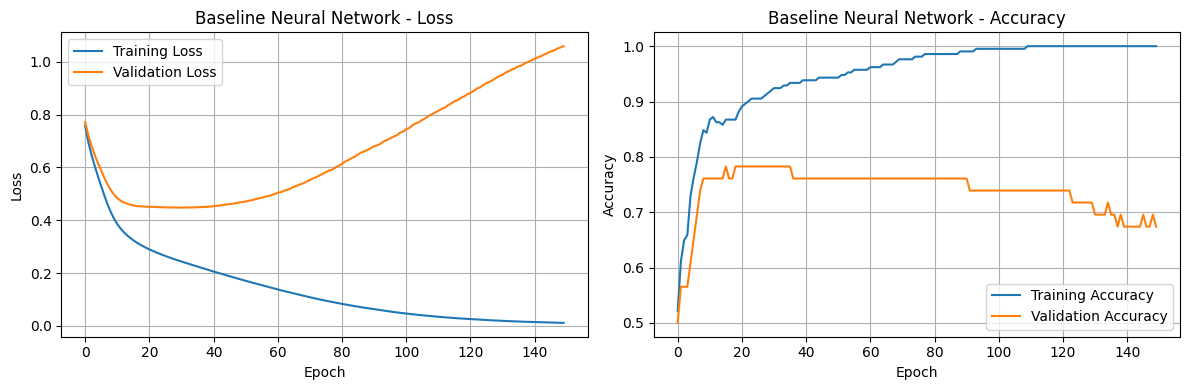

In [17]:

### Baseline Neural Network Training and Validation Curves
# Plot Baseline Neural Network training and validation curves

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
ax[0].plot(history_base.history["loss"], label="Training Loss")
ax[0].plot(history_base.history["val_loss"], label="Validation Loss")
ax[0].set_title("Baseline Neural Network - Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(True)

# Accuracy curves
ax[1].plot(history_base.history["accuracy"], label="Training Accuracy")
ax[1].plot(history_base.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("Baseline Neural Network - Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()


In [18]:
###  Neural Network Hyperparameter Optimization
# Import libraries for hyperparameter optimization

import itertools
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.base import clone
from tensorflow.keras import callbacks

# Set up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define hyperparameter search space
grid = {
    "units": [(16,), (32, 16)],
    "dropout": [0.0, 0.3],
    "l2": [0.0, 0.001, 0.01],
    "lr": [0.001, 0.01]
}

# Count hyperparameter combinations
total_combinations = len(list(itertools.product(*grid.values())))

print("Hyperparameter combinations:", total_combinations)
print("Total CV training runs:", total_combinations * 5)


Hyperparameter combinations: 24
Total CV training runs: 120


In [19]:

###Stratified Cross-Validation with Early Stopping
# Cross-validation with separate early stopping data

def cv_auc(params, seed=42):
    aucs = []

    for fold, (tr_idx, va_idx) in enumerate(
        cv.split(X_train, y_train), start=1
    ):
        # Separate training and evaluation fold
        X_tr_raw = X_train.iloc[tr_idx]
        X_va_raw = X_train.iloc[va_idx]

        y_tr = np.asarray(y_train.iloc[tr_idx])
        y_va = np.asarray(y_train.iloc[va_idx])

        # Internal split for early stopping
        X_fit, X_es, y_fit, y_es = train_test_split(
            X_tr_raw,
            y_tr,
            test_size=0.2,
            stratify=y_tr,
            random_state=seed
        )

        # Fit preprocessing on training data only
        pre = clone(preprocessor)

        Xf = pre.fit_transform(X_fit).astype("float32")
        Xe = pre.transform(X_es).astype("float32")
        Xv = pre.transform(X_va_raw).astype("float32")

        # Build a fresh Neural Network
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed + fold)

        model = build_model(Xf.shape[1], **params)

        early_stop = callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True
        )

        # Train model
        model.fit(
            Xf,
            y_fit,
            validation_data=(Xe, y_es),
            epochs=150,
            batch_size=16,
            callbacks=[early_stop],
            verbose=0
        )

        # Evaluate on held-out CV fold
        probabilities = model.predict(Xv, verbose=0).ravel()
        auc = roc_auc_score(y_va, probabilities)

        aucs.append(auc)

    return np.mean(aucs), np.std(aucs)


print("Cross-validation function is ready!")


Cross-validation function is ready!


In [20]:

# Grid Search for Neural Network Hyperparameters

results = []
keys = list(grid.keys())

for i, combo in enumerate(itertools.product(*grid.values()), start=1):

    params = dict(zip(keys, combo))

    mean_auc, std_auc = cv_auc(params)

    results.append({
        **params,
        "cv_auc": mean_auc,
        "cv_std": std_auc
    })

    print(
        f"{i}/24 | {params} | "
        f"CV ROC-AUC = {mean_auc:.4f}"
    )

# Create results table
res_df = pd.DataFrame(results).sort_values(
    "cv_auc", ascending=False
).reset_index(drop=True)

print("\nTop 10 Hyperparameter Combinations:")
display(res_df.head(10))

# Select best hyperparameters
best_params = {
    k: res_df.iloc[0][k]
    for k in keys
}

print("\nBest Hyperparameters:")
print(best_params)

print("\nBest Mean CV ROC-AUC:",
      round(res_df.iloc[0]["cv_auc"], 4))


1/24 | {'units': (16,), 'dropout': 0.0, 'l2': 0.0, 'lr': 0.001} | CV ROC-AUC = 0.9088
2/24 | {'units': (16,), 'dropout': 0.0, 'l2': 0.0, 'lr': 0.01} | CV ROC-AUC = 0.9052
3/24 | {'units': (16,), 'dropout': 0.0, 'l2': 0.001, 'lr': 0.001} | CV ROC-AUC = 0.9070
4/24 | {'units': (16,), 'dropout': 0.0, 'l2': 0.001, 'lr': 0.01} | CV ROC-AUC = 0.9060
5/24 | {'units': (16,), 'dropout': 0.0, 'l2': 0.01, 'lr': 0.001} | CV ROC-AUC = 0.9131
6/24 | {'units': (16,), 'dropout': 0.0, 'l2': 0.01, 'lr': 0.01} | CV ROC-AUC = 0.9094
7/24 | {'units': (16,), 'dropout': 0.3, 'l2': 0.0, 'lr': 0.001} | CV ROC-AUC = 0.9106
8/24 | {'units': (16,), 'dropout': 0.3, 'l2': 0.0, 'lr': 0.01} | CV ROC-AUC = 0.9124
9/24 | {'units': (16,), 'dropout': 0.3, 'l2': 0.001, 'lr': 0.001} | CV ROC-AUC = 0.9115
10/24 | {'units': (16,), 'dropout': 0.3, 'l2': 0.001, 'lr': 0.01} | CV ROC-AUC = 0.9146
11/24 | {'units': (16,), 'dropout': 0.3, 'l2': 0.01, 'lr': 0.001} | CV ROC-AUC = 0.9178
12/24 | {'units': (16,), 'dropout': 0.3, 'l2':

,units,dropout,l2,lr,cv_auc,cv_std
0,"(16,)",0.3,0.010,0.010,0.920125,0.026971
1,"(16,)",0.3,0.010,0.001,0.917848,0.020247
2,"(16,)",0.3,0.001,0.010,0.914632,0.026389
3,"(16,)",0.0,0.010,0.001,0.913102,0.026846
4,"(16,)",0.3,0.000,0.010,0.912412,0.026751
5,"(32, 16)",0.0,0.010,0.001,0.912127,0.018456
6,"(16,)",0.3,0.001,0.001,0.911476,0.023967
7,"(32, 16)",0.0,0.010,0.010,0.910859,0.018037
8,"(32, 16)",0.3,0.010,0.001,0.910747,0.017410
9,"(16,)",0.3,0.000,0.001,0.910577,0.025771



Best Hyperparameters:
{'units': (16,), 'dropout': np.float64(0.3), 'l2': np.float64(0.01), 'lr': np.float64(0.01)}

Best Mean CV ROC-AUC: 0.9201


In [21]:

# Train the tuned Neural Network

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Convert NumPy scalar values to Python floats
best_params = {
    "units": tuple(res_df.iloc[0]["units"]),
    "dropout": float(res_df.iloc[0]["dropout"]),
    "l2": float(res_df.iloc[0]["l2"]),
    "lr": float(res_df.iloc[0]["lr"])
}

# Build tuned model
final = build_model(
    Xtr.shape[1],
    **best_params
)

# Early stopping to reduce overfitting
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

# Train using training and validation sets
history_final = final.fit(
    Xtr,
    ytr,
    validation_data=(Xva, yva),
    epochs=300,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

# Display training information
print("Best Hyperparameters:", best_params)
print("Epochs Completed:", len(history_final.history["loss"]))
print("Best Epoch:", np.argmin(history_final.history["val_loss"]) + 1)

# Evaluate the restored model weights
train_loss, train_acc = final.evaluate(Xtr, ytr, verbose=0)
val_loss, val_acc = final.evaluate(Xva, yva, verbose=0)

print("Training Accuracy:", round(train_acc, 4))
print("Validation Accuracy:", round(val_acc, 4))
print("Training Loss:", round(train_loss, 4))
print("Validation Loss:", round(val_loss, 4))


Best Hyperparameters: {'units': (16,), 'dropout': 0.3, 'l2': 0.01, 'lr': 0.01}
Epochs Completed: 40
Best Epoch: 20
Training Accuracy: 0.9052
Validation Accuracy: 0.8043
Training Loss: 0.3015
Validation Loss: 0.4567


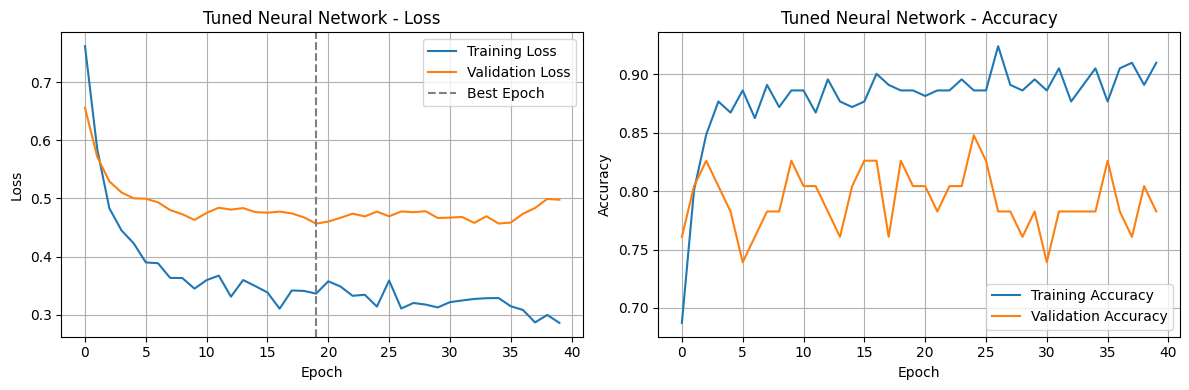

In [22]:

# Plot tuned Neural Network training and validation curves

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
ax[0].plot(
    history_final.history["loss"],
    label="Training Loss"
)
ax[0].plot(
    history_final.history["val_loss"],
    label="Validation Loss"
)
ax[0].axvline(
    np.argmin(history_final.history["val_loss"]),
    color="gray",
    linestyle="--",
    label="Best Epoch"
)
ax[0].set_title("Tuned Neural Network - Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(True)

# Accuracy curves
ax[1].plot(
    history_final.history["accuracy"],
    label="Training Accuracy"
)
ax[1].plot(
    history_final.history["val_accuracy"],
    label="Validation Accuracy"
)
ax[1].set_title("Tuned Neural Network - Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()


In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict probabilities on validation set
y_val_prob = final.predict(Xva, verbose=0).ravel()

# Convert probabilities into binary predictions
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Calculate validation metrics
val_accuracy = accuracy_score(yva, y_val_pred)
val_precision = precision_score(yva, y_val_pred, zero_division=0)
val_recall = recall_score(yva, y_val_pred, zero_division=0)
val_f1 = f1_score(yva, y_val_pred, zero_division=0)
val_auc = roc_auc_score(yva, y_val_prob)

print("Tuned Neural Network - Validation Results")
print("Accuracy:", round(val_accuracy, 4))
print("Precision:", round(val_precision, 4))
print("Recall:", round(val_recall, 4))
print("F1-Score:", round(val_f1, 4))
print("ROC-AUC:", round(val_auc, 4))


Tuned Neural Network - Validation Results
Accuracy: 0.8043
Precision: 0.8333
Recall: 0.7143
F1-Score: 0.7692
ROC-AUC: 0.8914


In [24]:

# Compare Baseline and Tuned Neural Networks
# Using the same validation set

def get_metrics(model, X, y):
    probabilities = model.predict(X, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y, probabilities)
    }

# Evaluate both models
baseline_metrics = get_metrics(base, Xva, yva)
tuned_metrics = get_metrics(final, Xva, yva)

# Create comparison table
comparison_df = pd.DataFrame({
    "Baseline NN": baseline_metrics,
    "Tuned NN": tuned_metrics
})

print("Neural Network Validation Comparison:")
display(comparison_df.round(4))


Neural Network Validation Comparison:


,Baseline NN,Tuned NN
Accuracy,0.6739,0.8043
Precision,0.6364,0.8333
Recall,0.6667,0.7143
F1-Score,0.6512,0.7692
ROC-AUC,0.8095,0.8914


Final Model Comparison - Test Set


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8913,0.8636,0.9048,0.8837,0.9448
1,Random Forest,0.8696,0.8571,0.8571,0.8571,0.9257
2,Neural Network,0.8478,0.7917,0.9048,0.8444,0.9371


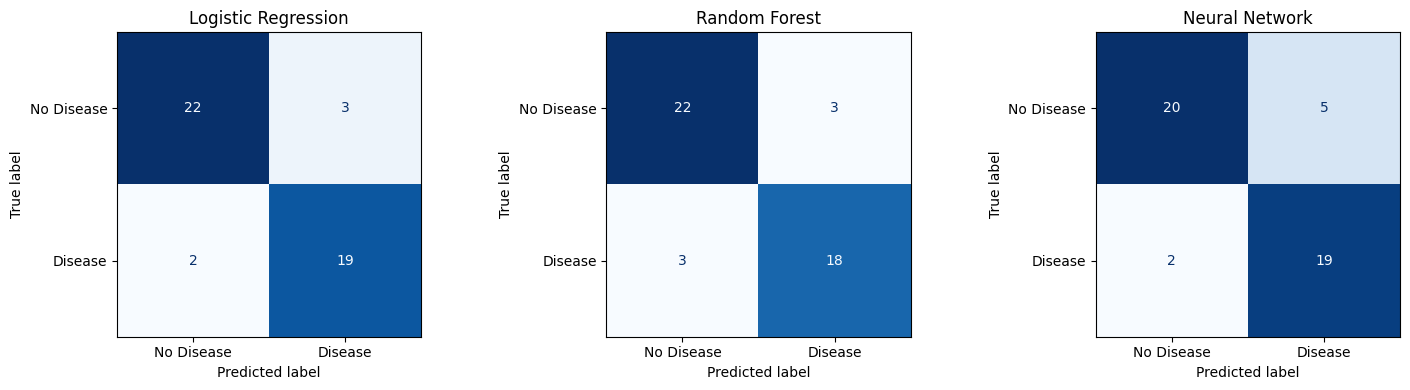

In [25]:
# Stage 5: Final Evaluation and Comparison

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Prepare the test data
Xte = X_test_p.astype("float32")
yte = np.asarray(y_test).astype(int)

# Define the selected models
models = {
    "Logistic Regression": tuned_models["Logistic Regression"],
    "Random Forest": tuned_models["Random Forest"],
    "Neural Network": final
}

test_results = []
confusion_matrices = {}

# Evaluate each model on the test set
for name, model in models.items():

    if name == "Neural Network":
        y_prob = model.predict(Xte, verbose=0).ravel()
        y_pred = (y_prob >= 0.5).astype(int)

    else:
        y_pred = model.predict(X_test_p)
        y_prob = model.predict_proba(X_test_p)[:, 1]

    accuracy = accuracy_score(yte, y_pred)
    precision = precision_score(yte, y_pred, zero_division=0)
    recall = recall_score(yte, y_pred, zero_division=0)
    f1 = f1_score(yte, y_pred, zero_division=0)
    auc = roc_auc_score(yte, y_prob)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    confusion_matrices[name] = confusion_matrix(
        yte, y_pred, labels=[0, 1]
    )

# Display the final comparison table
test_results_df = pd.DataFrame(test_results)

print("Final Model Comparison - Test Set")
display(test_results_df.round(4))

# Plot confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease", "Disease"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

